# Household Animals Classification Using Deep Learning

This Google Colab notebook follows the main workflow in the project report: a VGG-like CNN trained from scratch, dropout/data augmentation, VGG16 transfer learning, fine-tuning, evaluation plots, intermediate activations, and a class-activation heatmap.

**Dataset note:** This notebook uses the Microsoft Cats vs Dogs not the kaggle one.

**Runtime:** Google Colab with TensorFlow, GPU **Runtime → Change runtime type → T4 GPU**.

## 1. Download and extract the dataset

This downloads the Microsoft Cats vs Dogs archive and extracts it under `/content/catsdogs`.

In [1]:
import os
from pathlib import Path

SOURCE_ROOT = Path("/content/catsdogs/PetImages")
if not (SOURCE_ROOT / "Cat").is_dir() or not (SOURCE_ROOT / "Dog").is_dir():
    !wget -q --show-progress "https://download.microsoft.com/download/3/E/1/3E1C3F21-ECDB-4869-8368-6DEBA77B919F/kagglecatsanddogs_5340.zip" -O /content/catsdogs.zip
    !unzip -q /content/catsdogs.zip -d /content/catsdogs

print("Cat folder exists:", (SOURCE_ROOT / "Cat").is_dir())
print("Dog folder exists:", (SOURCE_ROOT / "Dog").is_dir())

Cat folder exists: True
Dog folder exists: True


## 2. Imports, verify images, and create 80/16/4 train/validation/test splits

Invalid/corrupted images are skipped. The split uses symlinks to avoid duplicating the image files.

In [2]:
import random
import shutil
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image, UnidentifiedImageError
from sklearn.model_selection import train_test_split
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.applications import VGG16

SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

SOURCE = Path("/content/catsdogs/PetImages")
SPLIT = Path("/content/animals_split")

if not (SOURCE / "Cat").is_dir() or not (SOURCE / "Dog").is_dir():
    raise FileNotFoundError("Dataset folders not found. Run the dataset download cell first.")

valid_files = {}
for class_name in ["Cat", "Dog"]:
    valid = []
    for path in (SOURCE / class_name).iterdir():
        if not path.is_file():
            continue
        try:
            with Image.open(path) as im:
                im.verify()
            valid.append(path)
        except (UnidentifiedImageError, OSError, ValueError):
            pass
    valid_files[class_name] = sorted(valid)
    print(f"{class_name}: {len(valid)} valid images")

if SPLIT.exists():
    shutil.rmtree(SPLIT)

for split_name in ["train", "val", "test"]:
    for class_name in ["Cat", "Dog"]:
        (SPLIT / split_name / class_name).mkdir(parents=True, exist_ok=True)

counts = {}
for class_name, files in valid_files.items():
    train_files, temp_files = train_test_split(
        files, test_size=0.20, random_state=SEED
    )
    val_files, test_files = train_test_split(
        temp_files, test_size=0.20, random_state=SEED
    )
    split_files = {
        "train": train_files,
        "val": val_files,
        "test": test_files,
    }
    for split_name, paths in split_files.items():
        target_dir = SPLIT / split_name / class_name
        for source_path in paths:
            destination = target_dir / source_path.name
            try:
                destination.symlink_to(source_path)
            except OSError:
                shutil.copy2(source_path, destination)
        counts[(split_name, class_name)] = len(paths)

for split_name in ["train", "val", "test"]:
    print(split_name, {c: counts[(split_name, c)] for c in ["Cat", "Dog"]})

Cat: 12499 valid images


/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Dog: 12499 valid images
train {'Cat': 9999, 'Dog': 9999}
val {'Cat': 2000, 'Dog': 2000}
test {'Cat': 500, 'Dog': 500}


## 3. Load datasets and preview images

The binary labels are assigned from the directory names. TensorFlow's directory loader sorts class names alphabetically, so `Cat` is label 0 and `Dog` is label 1.

Found 19998 files belonging to 2 classes.
Found 4000 files belonging to 2 classes.
Found 1000 files belonging to 2 classes.
Class order: ['Cat', 'Dog']


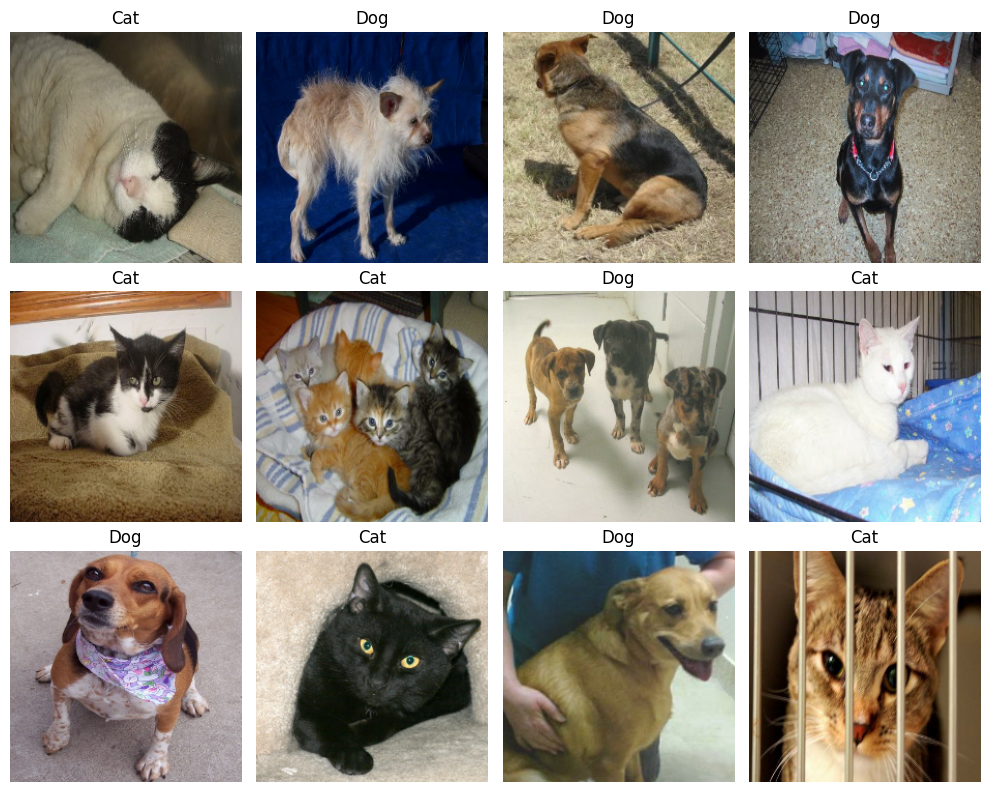

In [3]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    SPLIT / "train",
    label_mode="binary",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED,
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    SPLIT / "val",
    label_mode="binary",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
)
test_ds = tf.keras.utils.image_dataset_from_directory(
    SPLIT / "test",
    label_mode="binary",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

print("Class order:", train_ds.class_names)
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

images, labels = next(iter(train_ds))
plt.figure(figsize=(10, 8))
for i in range(min(12, len(images))):
    ax = plt.subplot(3, 4, i + 1)
    plt.imshow(tf.cast(images[i], tf.uint8).numpy())
    label = "Dog" if int(labels[i].numpy()[0]) == 1 else "Cat"
    plt.title(label)
    plt.axis("off")
plt.tight_layout()
plt.savefig("/content/sample_images.png", dpi=150)
plt.show()

In [4]:

from pathlib import Path
from PIL import Image
import shutil
import tensorflow as tf

SOURCE_SPLIT = Path("/content/animals_split")
CLEAN_SPLIT = Path("/content/animals_split_rgb")

if CLEAN_SPLIT.exists():
    shutil.rmtree(CLEAN_SPLIT)

for split_name in ["train", "val", "test"]:
    for class_name in ["Cat", "Dog"]:
        src_dir = SOURCE_SPLIT / split_name / class_name
        dst_dir = CLEAN_SPLIT / split_name / class_name
        dst_dir.mkdir(parents=True, exist_ok=True)

        cleaned, skipped = 0, 0

        for i, path in enumerate(src_dir.iterdir()):
            if not path.is_file():
                continue

            try:
                with Image.open(path) as img:
                    img.load()
                    rgb = img.convert("RGB")
                    rgb.save(
                        dst_dir / f"{i:06d}.jpg",
                        format="JPEG",
                        quality=95
                    )
                cleaned += 1
            except Exception:
                skipped += 1

        print(
            f"{split_name}/{class_name}: "
            f"{cleaned} cleaned, {skipped} skipped"
        )

# Switch to cleaned images and rebuild all datasets.
SPLIT = CLEAN_SPLIT
AUTOTUNE = tf.data.AUTOTUNE

train_ds = tf.keras.utils.image_dataset_from_directory(
    SPLIT / "train",
    label_mode="binary",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED,
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    SPLIT / "val",
    label_mode="binary",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    SPLIT / "test",
    label_mode="binary",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

# Confirm that TensorFlow can read a batch.
for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)

print("Dataset cleaning and loading complete.")


train/Cat: 9999 cleaned, 0 skipped
train/Dog: 9999 cleaned, 0 skipped
val/Cat: 2000 cleaned, 0 skipped
val/Dog: 2000 cleaned, 0 skipped
test/Cat: 500 cleaned, 0 skipped
test/Dog: 500 cleaned, 0 skipped
Found 19998 files belonging to 2 classes.
Found 4000 files belonging to 2 classes.
Found 1000 files belonging to 2 classes.
Image batch shape: (32, 224, 224, 3)
Label batch shape: (32, 1)
Dataset cleaning and loading complete.


## 4. Build and train the VGG-like CNN from scratch

The network uses 3×3 convolutions, ReLU activations, max pooling, and the filter progression 32/64/128/128, following the report's VGG-like architecture.

In [5]:

def vgg_like(augmentation=False, dropout=False):
    inputs = layers.Input(shape=(*IMG_SIZE, 3), name="image")
    x = inputs

    if augmentation:
        x = layers.RandomFlip(
            "horizontal", seed=SEED, name="random_flip"
        )(x)

    x = layers.Rescaling(1.0 / 255, name="rescaling")(x)

    # Block 1: 32 filters
    x = layers.Conv2D(32, 3, padding="same", activation="relu",
                      name="block1_conv1")(x)
    x = layers.Conv2D(32, 3, padding="same", activation="relu",
                      name="block1_conv2")(x)
    x = layers.MaxPooling2D(name="block1_pool")(x)

    # Block 2: 64 filters
    x = layers.Conv2D(64, 3, padding="same", activation="relu",
                      name="block2_conv1")(x)
    x = layers.Conv2D(64, 3, padding="same", activation="relu",
                      name="block2_conv2")(x)
    x = layers.MaxPooling2D(name="block2_pool")(x)

    # Block 3: 128 filters
    x = layers.Conv2D(128, 3, padding="same", activation="relu",
                      name="block3_conv1")(x)
    x = layers.Conv2D(128, 3, padding="same", activation="relu",
                      name="block3_conv2")(x)
    x = layers.MaxPooling2D(name="block3_pool")(x)

    # Block 4: 128 filters
    x = layers.Conv2D(128, 3, padding="same", activation="relu",
                      name="block4_conv1")(x)
    x = layers.MaxPooling2D(name="block4_pool")(x)

    x = layers.Flatten(name="flatten")(x)

    if dropout:
        x = layers.Dropout(0.5, name="dropout_flatten")(x)

    x = layers.Dense(128, activation="relu", name="dense_128")(x)

    if dropout:
        x = layers.Dropout(0.5, name="dropout_dense")(x)

    outputs = layers.Dense(1, activation="sigmoid",
                           name="predictions")(x)

    return models.Model(inputs, outputs, name="vgg_like_cnn")


baseline = vgg_like(augmentation=False, dropout=False)

baseline.compile(
    optimizer=optimizers.RMSprop(),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

baseline.summary()

EPOCHS_BASELINE = 20

history_baseline = baseline.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_BASELINE,
)

baseline.save("/content/vgg_like_baseline.keras")
print("Baseline model trained and saved successfully.")


Model: "vgg_like_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_128 (Dense)               │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,646,113 (13.91 MB)

 Trainable params: 3,646,113 (13.91 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 126s 172ms/step - accuracy: 0.5527 - loss: 0.6818 - val_accuracy: 0.6133 - val_loss: 0.6881
Epoch 2/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 91s 145ms/step - accuracy: 0.7060 - loss: 0.5673 - val_accuracy: 0.7412 - val_loss: 0.5203
Epoch 3/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 91s 146ms/step - accuracy: 0.7742 - loss: 0.4711 - val_accuracy: 0.8210 - val_loss: 0.4076
Epoch 4/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 142s 145ms/step - accuracy: 0.8213 - loss: 0.3918 - val_accuracy: 0.8298 - val_loss: 0.3832
Epoch 5/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 96s 154ms/step - accuracy: 0.8626 - loss: 0.3159 - val_accuracy: 0.8487 - val_loss: 0.3611
Epoch 6/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 92s 147ms/step - accuracy: 0.8957 - loss: 0.2501 - val_accuracy: 0.8043 - val_loss: 0.4790
Epoch 7/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 97s 154ms/step - accuracy: 0.9227 - loss: 0.1942 - val_accuracy: 0.8695 - val_loss: 0.3453
Epoch 8/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 92s 146ms/step - accuracy: 0.9412 - loss:

## 5. Train a VGG-like CNN with dropout and data augmentation

This model adds horizontal-flip augmentation and dropout to help reduce overfitting.

In [6]:
aug_model = vgg_like(augmentation=True, dropout=True)
aug_model.compile(
    optimizer=optimizers.RMSprop(),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)
aug_model.summary()

EPOCHS_AUGMENTED = 20
history_augmented = aug_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_AUGMENTED,
)
aug_model.save("/content/vgg_like_dropout_augmentation.keras")

Model: "vgg_like_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_flatten (Dropout)       │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_128 (Dense)               │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_dense (Dropout)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,646,113 (13.91 MB)

 Trainable params: 3,646,113 (13.91 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 108s 156ms/step - accuracy: 0.5274 - loss: 0.6895 - val_accuracy: 0.6100 - val_loss: 0.6570
Epoch 2/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 96s 154ms/step - accuracy: 0.6593 - loss: 0.6144 - val_accuracy: 0.7207 - val_loss: 0.5433
Epoch 3/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 97s 154ms/step - accuracy: 0.7267 - loss: 0.5382 - val_accuracy: 0.7868 - val_loss: 0.4532
Epoch 4/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 92s 147ms/step - accuracy: 0.7859 - loss: 0.4603 - val_accuracy: 0.7945 - val_loss: 0.4461
Epoch 5/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 92s 147ms/step - accuracy: 0.8233 - loss: 0.3921 - val_accuracy: 0.8198 - val_loss: 0.3938
Epoch 6/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 97s 155ms/step - accuracy: 0.8485 - loss: 0.3446 - val_accuracy: 0.8860 - val_loss: 0.2766
Epoch 7/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 136s 146ms/step - accuracy: 0.8738 - loss: 0.3014 - val_accuracy: 0.8928 - val_loss: 0.2574
Epoch 8/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 92s 147ms/step - accuracy: 0.8894 - loss:

## 6. VGG16 transfer learning

The ImageNet-pretrained VGG16 convolutional base is frozen while a new binary classifier is trained. Horizontal-flip augmentation is applied before VGG16 preprocessing.

In [7]:
vgg_base = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(*IMG_SIZE, 3),
)
vgg_base.trainable = False

vgg_input = layers.Input(shape=(*IMG_SIZE, 3), name="image")
x = layers.RandomFlip("horizontal", seed=SEED, name="vgg_random_flip")(vgg_input)
x = layers.Lambda(
    tf.keras.applications.vgg16.preprocess_input,
    name="vgg16_preprocess",
)(x)
feature_map_tensor = vgg_base(x, training=False)
x = layers.GlobalAveragePooling2D(name="global_average_pooling")(feature_map_tensor)
x = layers.Dense(128, activation="relu", name="classifier_dense")(x)
vgg_output = layers.Dense(1, activation="sigmoid", name="predictions")(x)

vgg_model = models.Model(vgg_input, vgg_output, name="vgg16_transfer")
vgg_model.compile(
    optimizer=optimizers.RMSprop(),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)
vgg_model.summary()

EPOCHS_TRANSFER = 20
history_transfer = vgg_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_TRANSFER,
)
transfer_test_loss, transfer_test_accuracy = vgg_model.evaluate(test_ds, verbose=1)
print(f"VGG16 transfer test accuracy: {transfer_test_accuracy:.4f}")
vgg_model.save("/content/vgg16_transfer.keras")

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


Model: "vgg16_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg_random_flip (RandomFlip)    │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16_preprocess (Lambda)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier_dense (Dense)        │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,780,481 (56.38 MB)

 Trainable params: 65,793 (257.00 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

Epoch 1/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 117s 178ms/step - accuracy: 0.9717 - loss: 0.1045 - val_accuracy: 0.9795 - val_loss: 0.0712
Epoch 2/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 105s 168ms/step - accuracy: 0.9864 - loss: 0.0456 - val_accuracy: 0.9858 - val_loss: 0.0570
Epoch 3/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 106s 169ms/step - accuracy: 0.9894 - loss: 0.0344 - val_accuracy: 0.9862 - val_loss: 0.0490
Epoch 4/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 105s 168ms/step - accuracy: 0.9907 - loss: 0.0298 - val_accuracy: 0.9808 - val_loss: 0.0670
Epoch 5/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 106s 169ms/step - accuracy: 0.9933 - loss: 0.0244 - val_accuracy: 0.9852 - val_loss: 0.0562
Epoch 6/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 106s 169ms/step - accuracy: 0.9942 - loss: 0.0203 - val_accuracy: 0.9870 - val_loss: 0.0567
Epoch 7/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 109s 174ms/step - accuracy: 0.9948 - loss: 0.0190 - val_accuracy: 0.9845 - val_loss: 0.0722
Epoch 8/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 106s 169ms/step - accuracy: 0.9957 -

## 7. Fine-tune VGG16 from `block5_conv1`

Unfreeze the later VGG16 layers starting at `block5_conv1`, keep earlier layers frozen, and use a low learning rate.

In [8]:
vgg_base.trainable = True
fine_tune = False
for layer in vgg_base.layers:
    if layer.name == "block5_conv1":
        fine_tune = True
    layer.trainable = fine_tune

print("Trainable VGG16 layers:")
for layer in vgg_base.layers:
    if layer.trainable:
        print(layer.name)

vgg_model.compile(
    optimizer=optimizers.RMSprop(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

EPOCHS_FINE_TUNE = 10
history_finetuned = vgg_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FINE_TUNE,
)
vgg_model.save("/content/vgg16_finetuned.keras")

Trainable VGG16 layers:
block5_conv1
block5_conv2
block5_conv3
block5_pool
Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 129s 198ms/step - accuracy: 0.9989 - loss: 0.0050 - val_accuracy: 0.9835 - val_loss: 0.1496
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 119s 190ms/step - accuracy: 0.9990 - loss: 0.0042 - val_accuracy: 0.9843 - val_loss: 0.1257
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 118s 189ms/step - accuracy: 0.9994 - loss: 0.0023 - val_accuracy: 0.9847 - val_loss: 0.1341
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 143s 190ms/step - accuracy: 0.9995 - loss: 0.0015 - val_accuracy: 0.9830 - val_loss: 0.1526
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 119s 190ms/step - accuracy: 0.9995 - loss: 0.0027 - val_accuracy: 0.9855 - val_loss: 0.1301
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 119s 190ms/step - accuracy: 0.9995 - loss: 0.0014 - val_accuracy: 0.9843 - val_loss: 0.1339
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 118s 189ms/step - accuracy: 0.9997 - loss: 9.6084e-04 - val_accuracy: 0.9847 - val_loss: 0.13

## 8. Plot training and validation accuracy/loss

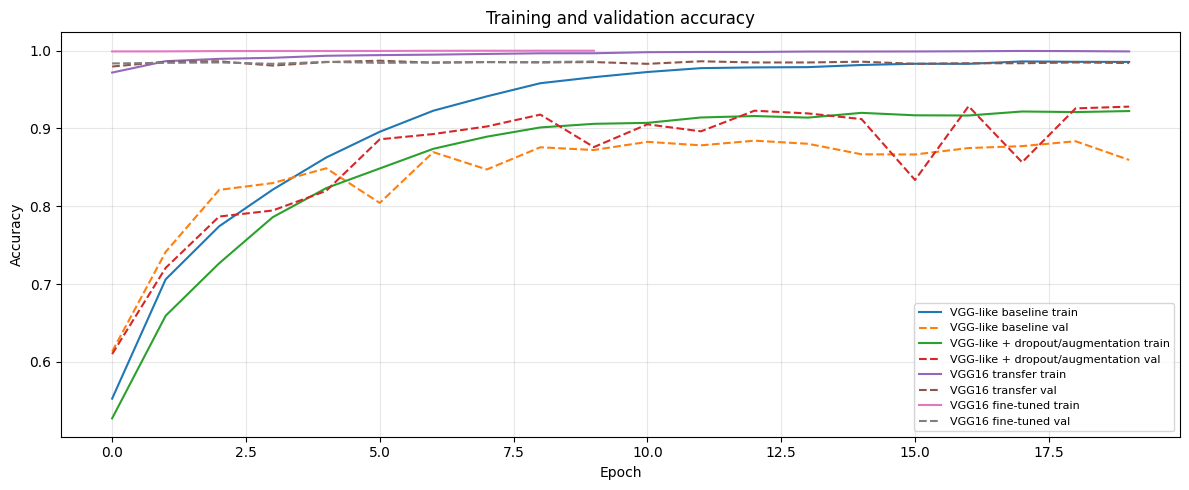

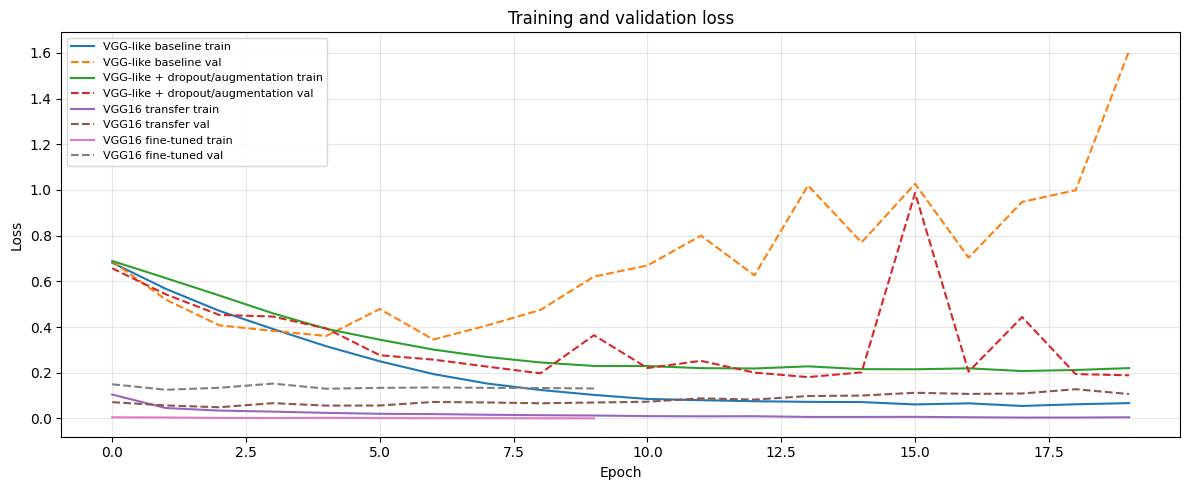

In [9]:
histories = [
    ("VGG-like baseline", history_baseline),
    ("VGG-like + dropout/augmentation", history_augmented),
    ("VGG16 transfer", history_transfer),
    ("VGG16 fine-tuned", history_finetuned),
]

plt.figure(figsize=(12, 5))
for name, hist in histories:
    plt.plot(hist.history["accuracy"], label=f"{name} train")
    plt.plot(hist.history["val_accuracy"], linestyle="--", label=f"{name} val")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and validation accuracy")
plt.legend(fontsize=8)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("/content/accuracy_curves.png", dpi=150)
plt.show()

plt.figure(figsize=(12, 5))
for name, hist in histories:
    plt.plot(hist.history["loss"], label=f"{name} train")
    plt.plot(hist.history["val_loss"], linestyle="--", label=f"{name} val")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and validation loss")
plt.legend(fontsize=8)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("/content/loss_curves.png", dpi=150)
plt.show()

## 9. Evaluate models on the test set

In [10]:
results = {}

for name, model in [
    ("VGG-like baseline", baseline),
    ("VGG-like dropout + augmentation", aug_model),
    ("VGG16 fine-tuned", vgg_model),
]:
    loss, accuracy = model.evaluate(test_ds, verbose=0)
    results[name] = {"test_loss": float(loss), "test_accuracy": float(accuracy)}

results["VGG16 transfer before fine-tuning"] = {
    "test_loss": float(transfer_test_loss),
    "test_accuracy": float(transfer_test_accuracy),
}

for name, metrics in results.items():
    print(f"{name}: loss={metrics['test_loss']:.4f}, accuracy={metrics['test_accuracy']:.4f}")

VGG-like baseline: loss=1.6643, accuracy=0.8510
VGG-like dropout + augmentation: loss=0.1856, accuracy=0.9220
VGG16 fine-tuned: loss=0.0951, accuracy=0.9860
VGG16 transfer before fine-tuning: loss=0.1036, accuracy=0.9840


## 10. Visualize intermediate activations

Show feature maps from early convolutional layers of the dropout/augmentation model for one test image.

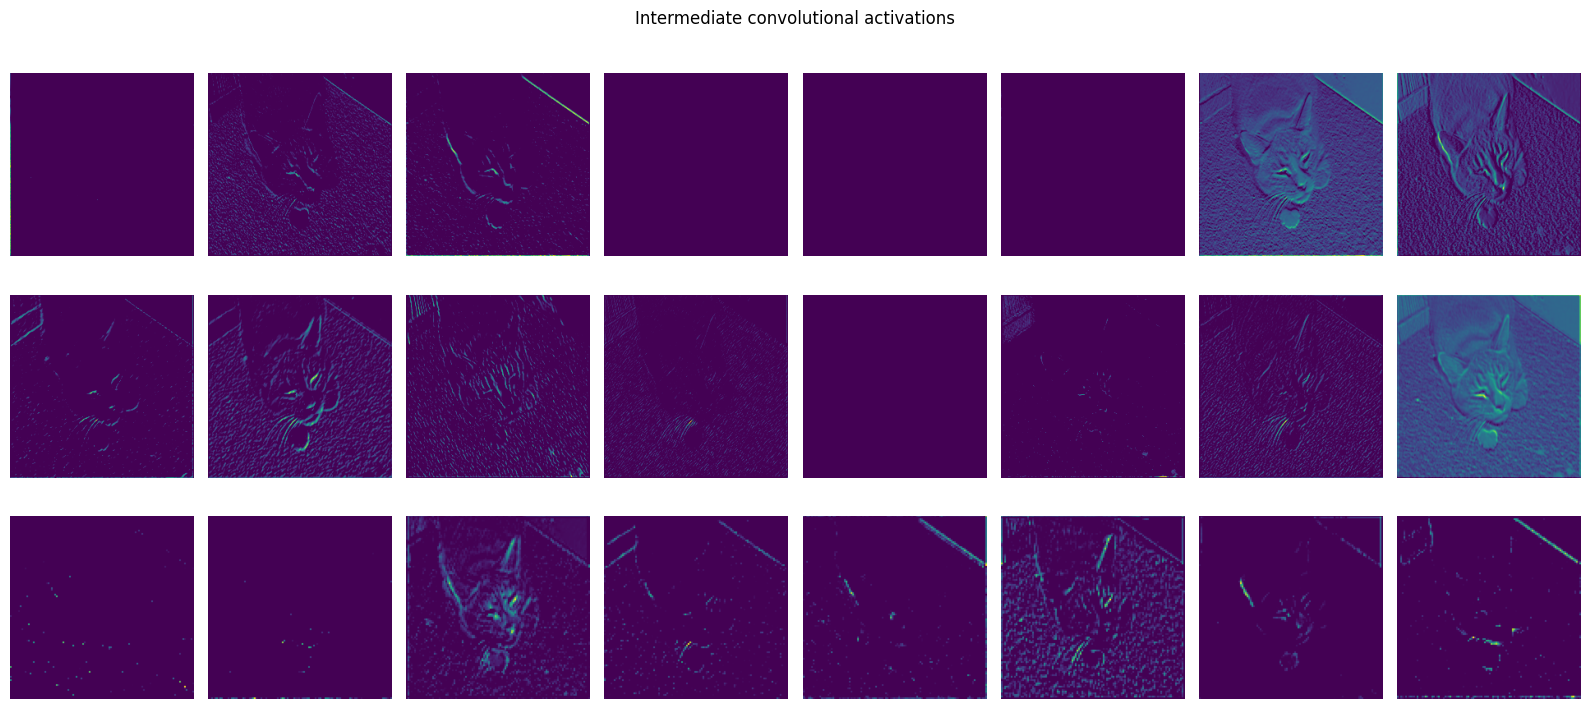

In [11]:
sample_images, sample_labels = next(iter(test_ds))
sample_image = sample_images[:1]

conv_layers = [
    layer for layer in aug_model.layers
    if isinstance(layer, layers.Conv2D)
][:3]

activation_model = models.Model(
    inputs=aug_model.input,
    outputs=[layer.output for layer in conv_layers],
)
activations = activation_model.predict(sample_image, verbose=0)

fig, axes = plt.subplots(len(activations), 8, figsize=(16, 2.5 * len(activations)))
if len(activations) == 1:
    axes = np.expand_dims(axes, axis=0)

for row, (layer, activation) in enumerate(zip(conv_layers, activations)):
    for col in range(8):
        ax = axes[row, col]
        ax.imshow(activation[0, :, :, col], cmap="viridis")
        ax.axis("off")
        if col == 0:
            ax.set_ylabel(layer.name, rotation=0, labelpad=55, va="center")
plt.suptitle("Intermediate convolutional activations")
plt.tight_layout()
plt.savefig("/content/intermediate_activations.png", dpi=150)
plt.show()

## 11. Grad-CAM class-activation heatmap for VGG16

Grad-CAM highlights image regions that influence the model's dog score. It is a gradient-based class-activation visualization related to, but not exactly the same as, the original CAM method.

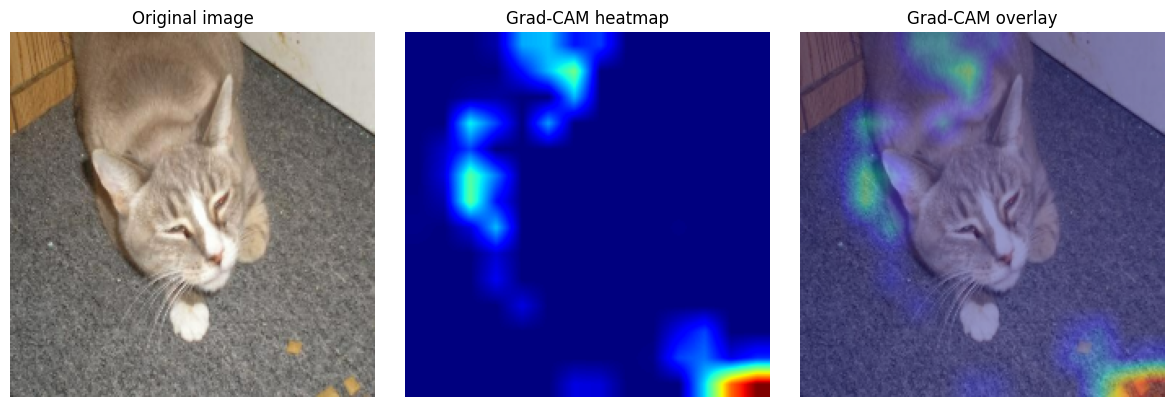

Prediction: Cat (dog probability=0.0000)


In [16]:

# Cell 11: Grad-CAM class-activation heatmap for VGG16

# Get the last convolutional layer from the VGG16 base.
last_conv_layer = vgg_base.get_layer("block5_conv3")

# Build a feature extractor for the last convolutional layer.
conv_model = models.Model(
    inputs=vgg_base.inputs,
    outputs=last_conv_layer.output
)

# Get one image from the test dataset.
image_batch, label_batch = next(iter(test_ds))
image_tensor = image_batch[:1]

# Rebuild the classification head without passing unsupported arguments.
with tf.GradientTape() as tape:
    conv_outputs = conv_model(image_tensor, training=False)
    tape.watch(conv_outputs)

    x = conv_outputs

    # Apply the layers after the VGG16 base.
    base_found = False
    for layer in vgg_model.layers:
        if layer is vgg_base:
            base_found = True
            continue
        if base_found:
            x = layer(x)

    predictions = x
    dog_score = predictions[:, 0]

# Calculate gradients.
grads = tape.gradient(dog_score, conv_outputs)

if grads is None:
    raise ValueError(
        "Gradients are unavailable. The VGG16 classifier may not "
        "be connected to vgg_base as expected."
    )

# Generate the Grad-CAM heatmap.
weights = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
heatmap = tf.reduce_sum(weights * conv_outputs, axis=-1)
heatmap = tf.nn.relu(heatmap)[0]

heatmap = heatmap / (
    tf.reduce_max(heatmap) + tf.keras.backend.epsilon()
)

heatmap = tf.image.resize(
    heatmap[..., tf.newaxis], IMG_SIZE
).numpy().squeeze()

# Display results.
original = tf.cast(image_tensor[0], tf.uint8).numpy()

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(original)
plt.title("Original image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap, cmap="jet")
plt.title("Grad-CAM heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(original)
plt.imshow(heatmap, cmap="jet", alpha=0.4)
plt.title("Grad-CAM overlay")
plt.axis("off")

plt.tight_layout()
plt.savefig("/content/cam_heatmap.png", dpi=150)
plt.show()

dog_probability = float(predictions.numpy()[0, 0])
predicted_class = "Dog" if dog_probability >= 0.5 else "Cat"

print(
    f"Prediction: {predicted_class} "
    f"(dog probability={dog_probability:.4f})"
)


## 12. Export models, plots, and test metrics

This creates one ZIP file with the trained models, figures, and JSON test metrics. Download the notebook separately from Colab if you also need the `.ipynb` file.

In [17]:
import json
import shutil
from pathlib import Path

OUT = Path("/content/Household_Animals_Classification_Deliverables")
MODELS_DIR = OUT / "models"
RESULTS_DIR = OUT / "results"

if OUT.exists():
    shutil.rmtree(OUT)
MODELS_DIR.mkdir(parents=True)
RESULTS_DIR.mkdir(parents=True)

model_paths = [
    Path("/content/vgg_like_baseline.keras"),
    Path("/content/vgg_like_dropout_augmentation.keras"),
    Path("/content/vgg16_transfer.keras"),
    Path("/content/vgg16_finetuned.keras"),
]
for path in model_paths:
    if path.exists():
        shutil.copy2(path, MODELS_DIR / path.name)
    else:
        print("Model file not found (perhaps its training cell was not run):", path)

for path in Path("/content").glob("*.png"):
    shutil.copy2(path, RESULTS_DIR / path.name)

with open(RESULTS_DIR / "test_results.json", "w") as f:
    json.dump(results, f, indent=2)

zip_path = shutil.make_archive(
    "/content/Household_Animals_Classification_Final",
    "zip",
    root_dir=OUT,
)
print("Created:", zip_path)
print("Contents:")
for path in sorted(OUT.rglob("*")):
    if path.is_file():
        print(path.relative_to(OUT))

Created: /content/Household_Animals_Classification_Final.zip
Contents:
models/vgg16_finetuned.keras
models/vgg16_transfer.keras
models/vgg_like_baseline.keras
models/vgg_like_dropout_augmentation.keras
results/accuracy_curves.png
results/cam_heatmap.png
results/intermediate_activations.png
results/loss_curves.png
results/sample_images.png
results/test_results.json


## Optional: download the deliverables ZIP from Colab

Run this cell after the export cell if you want to download the models and result images.

In [ ]:
from google.colab import files
files.download("/content/Household_Animals_Classification_Final.zip")